### Binary Saturation

This notebooks purpose is to simply do a sanity check on the analytical expressions found to describe the number of photons *lost* on an APD because of **binary saturation**. Quandelas software provides a plataform to simulate and use photonic quantum computers, implementing linear optics tools. The basics of *perceval*, their programming kit, is described on another notebook *Perceval-Learning*, where a description of how their computer works is also given. I will not delve deeper into this, in order to mantain the purpose of this notebook. However the basic idea is that they have quantum dot based single photon emmitters and can implement any unitary using a combination of beam-splitters and phase shifters. They also have Photon Number Resolving (PNR) detectors, which can also be set to work as an APD, by simply setting the threhsold of photons counted to 1. We can choose detector efficiencis and set many noise models to their circuits, which simulate our own setup.

There are of course many differences that need to be accounted for, since we will not be using light with a thermal statistics, nor are we using SPDC to produce the photon pairs. However for the purpose of simply testing how many photons we lose due to binary saturation this works fairly well.

In [21]:
!pip install perceval-quandela

In [22]:
# Install packages if missing (needed on Google Colab; no-op in Codespaces).
import importlib.util, subprocess, sys
if importlib.util.find_spec("perceval") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet",
                           "perceval-quandela"])

from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
import perceval as pcvl
from perceval.simulators import Simulator
from perceval.backends import SLOSBackend

plt.rcParams.update({"figure.figsize": (6, 4), "font.size": 12,
                     "axes.grid": True, "grid.alpha": 0.3})
print("perceval", pcvl.__version__)

# Crisp plots on projectors and HiDPI screens (works on Colab too).
%config InlineBackend.figure_format = "retina"

perceval 1.3.0



One first experiment is simply to understand the average number of photons lost on APDs when comparing with PNR detectors:
$$
\Delta N = \langle N^{PNR}_{det}\rangle - \langle N^{APD}_{det}\rangle = \eta^2
$$

Where $\eta$ is the detector efficiency and we assume that $\eta^{PNR} = \eta^{APD}$. In this case we should be able to test it fairly simple, since we will have detectors of the same efficiency and we must simply impose on our PNR detector to work as an APD.



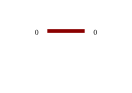

In [23]:
circuit = pcvl.Circuit(1)
pcvl.pdisplay(circuit)

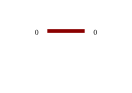

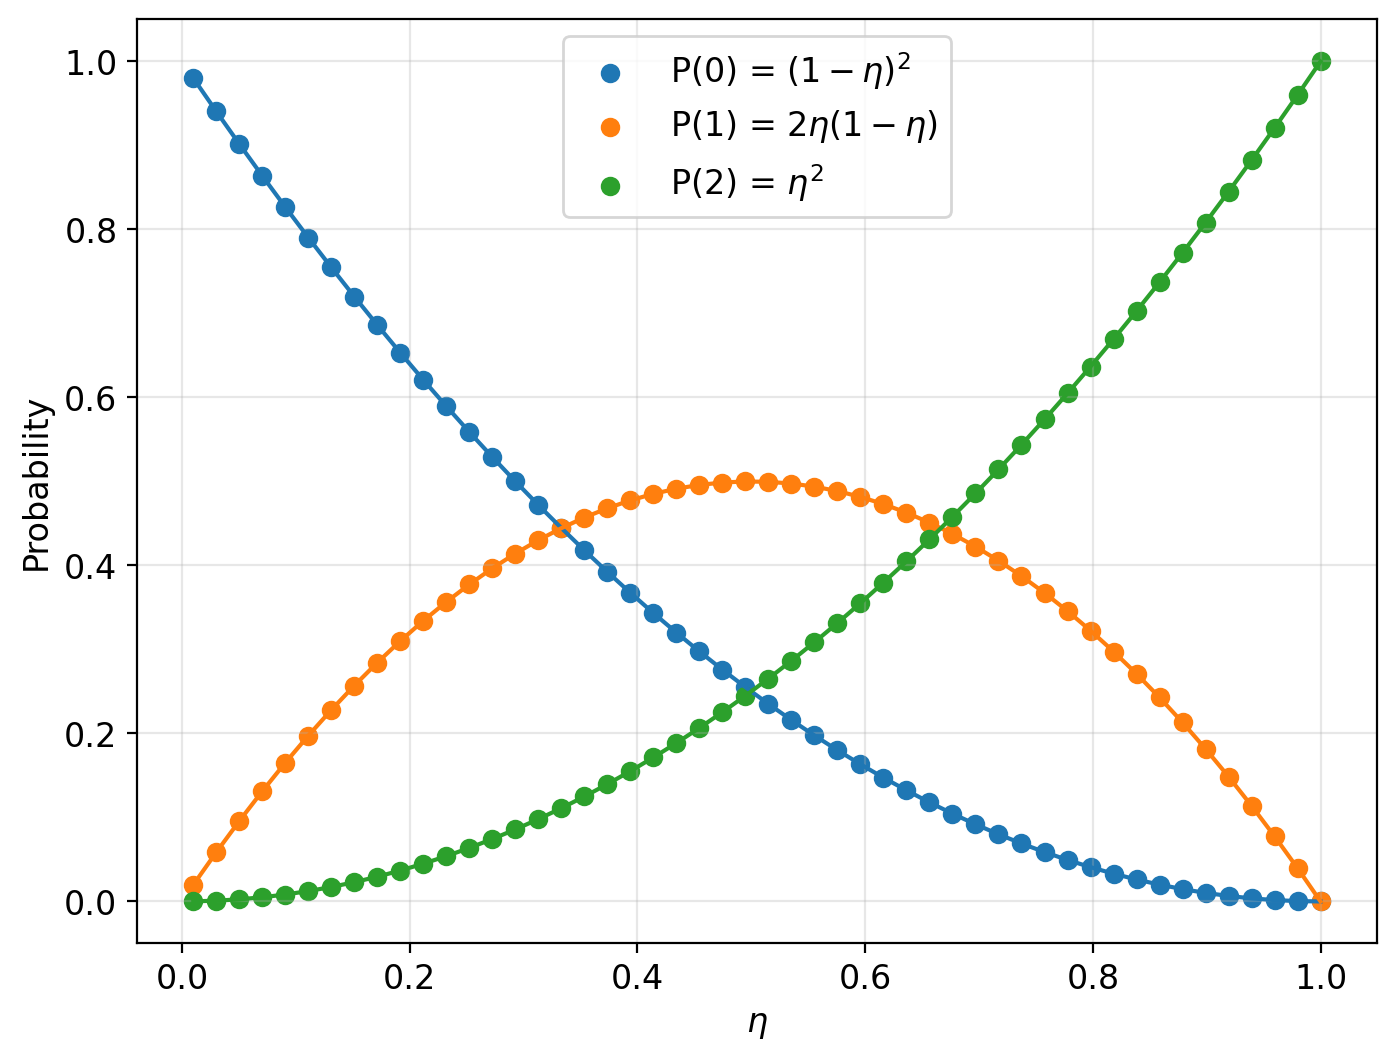

In [24]:

def simple():
    return pcvl.Circuit(1)

etas = np.linspace(0.01, 1, 50)


state = pcvl.BasicState('|2>') # estado inicial = estado final (reflexao)
result=[]
p0=[]
p1=[]
p2=[]

for eta in etas:
    proc = pcvl.Processor("SLOS", simple())
    detector = pcvl.Detector.pnr() # PNR
    detector.efficiency = eta # efficiency

    proc.add(0, detector)

    proc.with_input(state)
    proc.min_detected_photons_filter(0) ### detecta com no minimo 1 fóton
    res = pcvl.algorithm.Sampler(proc).probs()['results']
    result.append(res)
    p0.append(res.get(pcvl.BasicState([0]), 0.0))
    p1.append(res.get(pcvl.BasicState([1]), 0.0))
    p2.append(res.get(pcvl.BasicState([2]), 0.0))

### Expected results:

p0_ = lambda x: (1-x)**2
p1_ = lambda x: 2*x*(1-x)
p2_ = lambda x: x**2

po_points = [p0_(eta) for eta in etas]
p1_points = [p1_(eta) for eta in etas]
p2_points = [p2_(eta) for eta in etas]


circuit = simple()
display(pcvl.pdisplay(circuit))

fig, (ax1) = plt.subplots(1,1, figsize=(8, 6))

ax1.scatter(etas, p0, label = r'P(0) = $(1-\eta)^2$')
ax1.scatter(etas, p1, label = r'P(1) = $2\eta(1 - \eta)$')
ax1.scatter(etas, p2, label = r'P(2) = $\eta^2$')

ax1.plot(etas, po_points)
ax1.plot(etas, p1_points)
ax1.plot(etas, p2_points)

ax1.set_xlabel(r'$\eta$')
ax1.set_ylabel(r'Probability')


plt.legend()
plt.show()

Notice that it works just as expected for the PNDs. For the APDs it is not as trivial, but we will attempt to model it to count two photons as one and check if the expected value difference is still matching what we expect.


So by determining a threshold detector we do just that, even if more then 1 photon we still count a state of $|1\rangle$. So we will use this as our APD, let's run the same test with this new detector and see what we will get.

In [25]:
from perceval.components import Detector
det = Detector.threshold()  #
det.detect(5)

|1>

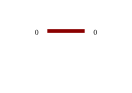

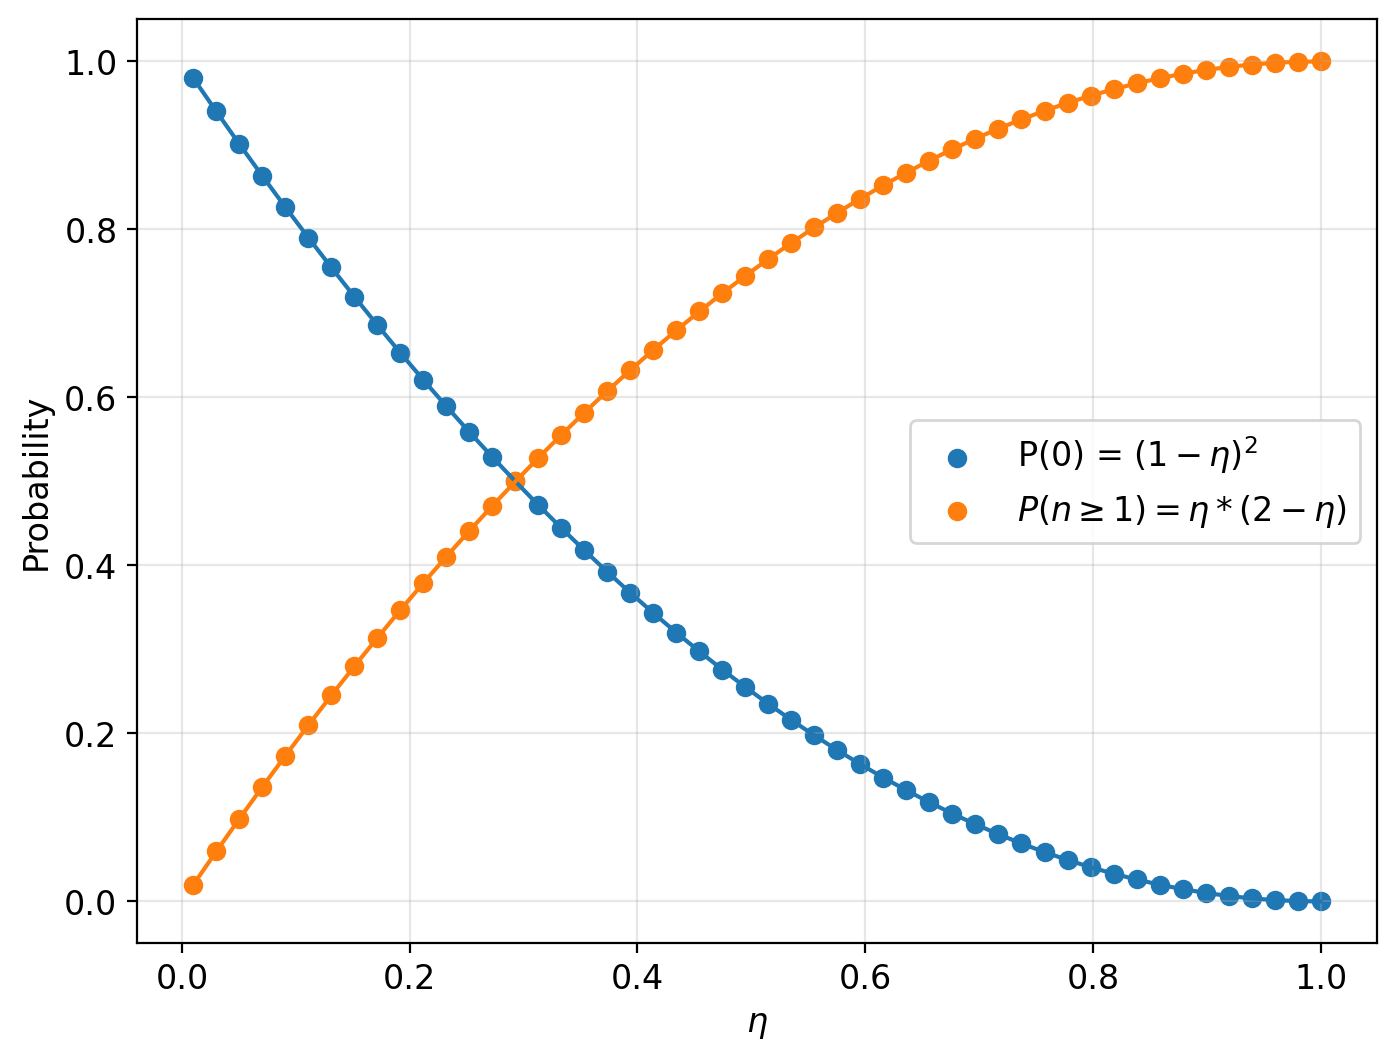

In [26]:

def simple():
    return pcvl.Circuit(1)

etas = np.linspace(0.01, 1, 50)


state = pcvl.BasicState('|2>') # estado inicial = estado final (reflexao)
result=[]
p0_APD=[]
p1_APD=[]
p2_APD=[]

for eta in etas:
    proc = pcvl.Processor("SLOS", simple())


    proc.with_input(state)

    detector = pcvl.Detector.threshold() # PNR
    detector.efficiency = eta # efficiency
    proc.add(0, detector)

    proc.min_detected_photons_filter(0) ### detecta com no minimo 1 fóton
    res = pcvl.algorithm.Sampler(proc).probs()['results']
    result.append(res)
    p0_APD.append(res.get(pcvl.BasicState([0]), 0.0))
    p1_APD.append(res.get(pcvl.BasicState([1]), 0.0))
    p2_APD.append(res.get(pcvl.BasicState([2]), 0.0))

### Expected results:

p0_ = lambda x: (1-x)**2
pgeq1 = lambda x: x*(2-x)

po_points = [p0_(eta) for eta in etas]
pgeq1_points = [pgeq1(eta) for eta in etas]



circuit = simple()
display(pcvl.pdisplay(circuit))

fig, (ax1) = plt.subplots(1,1, figsize=(8, 6))

ax1.scatter(etas, p0_APD, label = r'P(0) = $(1-\eta)^2$')
ax1.scatter(etas, p1_APD, label = r'$P(n \geq 1) = \eta*(2 - \eta)$')

plt.plot(etas, po_points)
plt.plot(etas, pgeq1_points)


ax1.set_xlabel(r'$\eta$')
ax1.set_ylabel(r'Probability')


plt.legend()
plt.show()

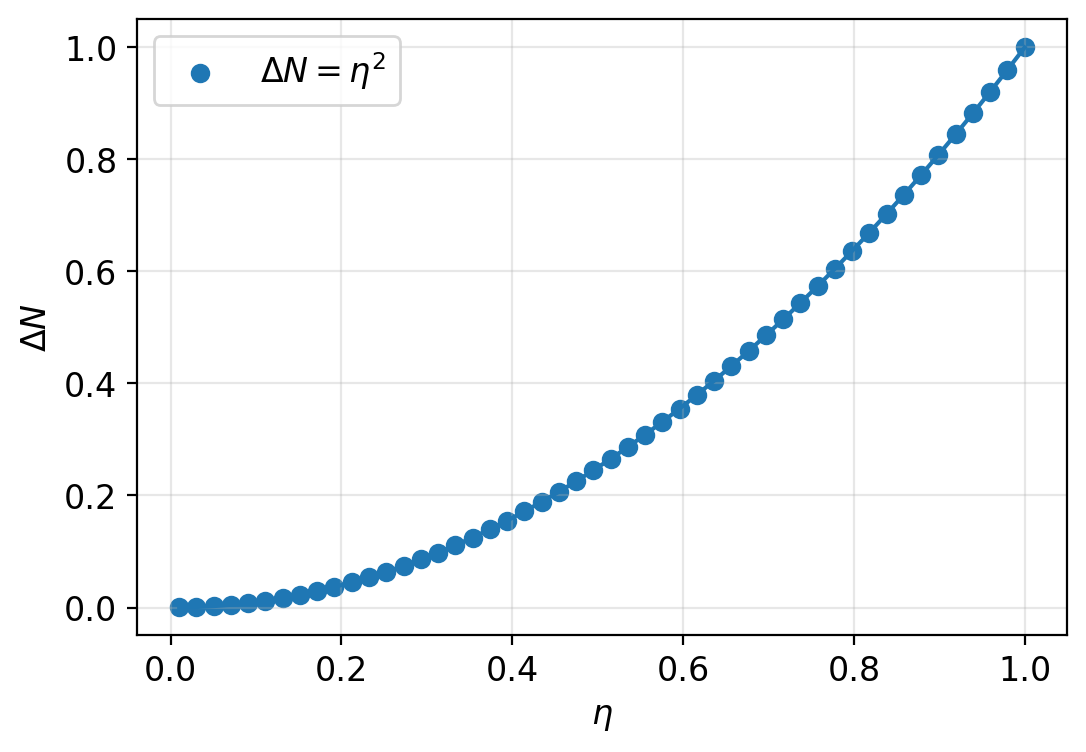

In [27]:
average_apd = np.array([ p0_APD[i]*0 + p1_APD[i]*1 for i in range(len(p0_APD))])
average_pnr = np.array([ p0[i]*0 + p1[i]*1 + p2[i]*2 for i in range(len(p0))])


avg_exp = lambda x : x**2

delta_N = average_pnr - average_apd


plt.scatter(etas, delta_N, label = r'$\Delta N = \eta^2$')
plt.plot(etas, [avg_exp(eta) for eta in etas])


plt.xlabel(r'$\eta$')
plt.ylabel(r'$\Delta N$')
plt.legend()
plt.show()

Now we can add a beam-splitter and check if the expressions found to correct for the loss due to binary saturation works. In order to do this we will simply build a circuit with two possible paths and a beam-splitter with a varying transmitance, which can be modelled by simply changing it´s angle. We are interested in changing the transmitance, because both expressions found to correct for the losses are given in terms of reflectance and transmitance (and efficiencies but for now this won´t be considered).

We expect that for PNR detectors we will always be able to fully account for the photons arriving, since 2 photon arrival is resolved for PNRs. However with the APDs we will find that for transmitance values that maximize coincidence counts we will be underestimating the number of photons arriving. If the expressions are correct by adding their correction factor we will recover the expected number of photons.

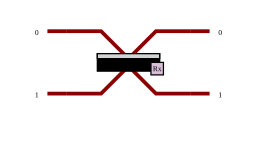

In [28]:
def coincidence(theta):
  return pcvl.Circuit(2)//pcvl.BS(theta = theta)

display(pcvl.pdisplay(coincidence(np.pi/2)))

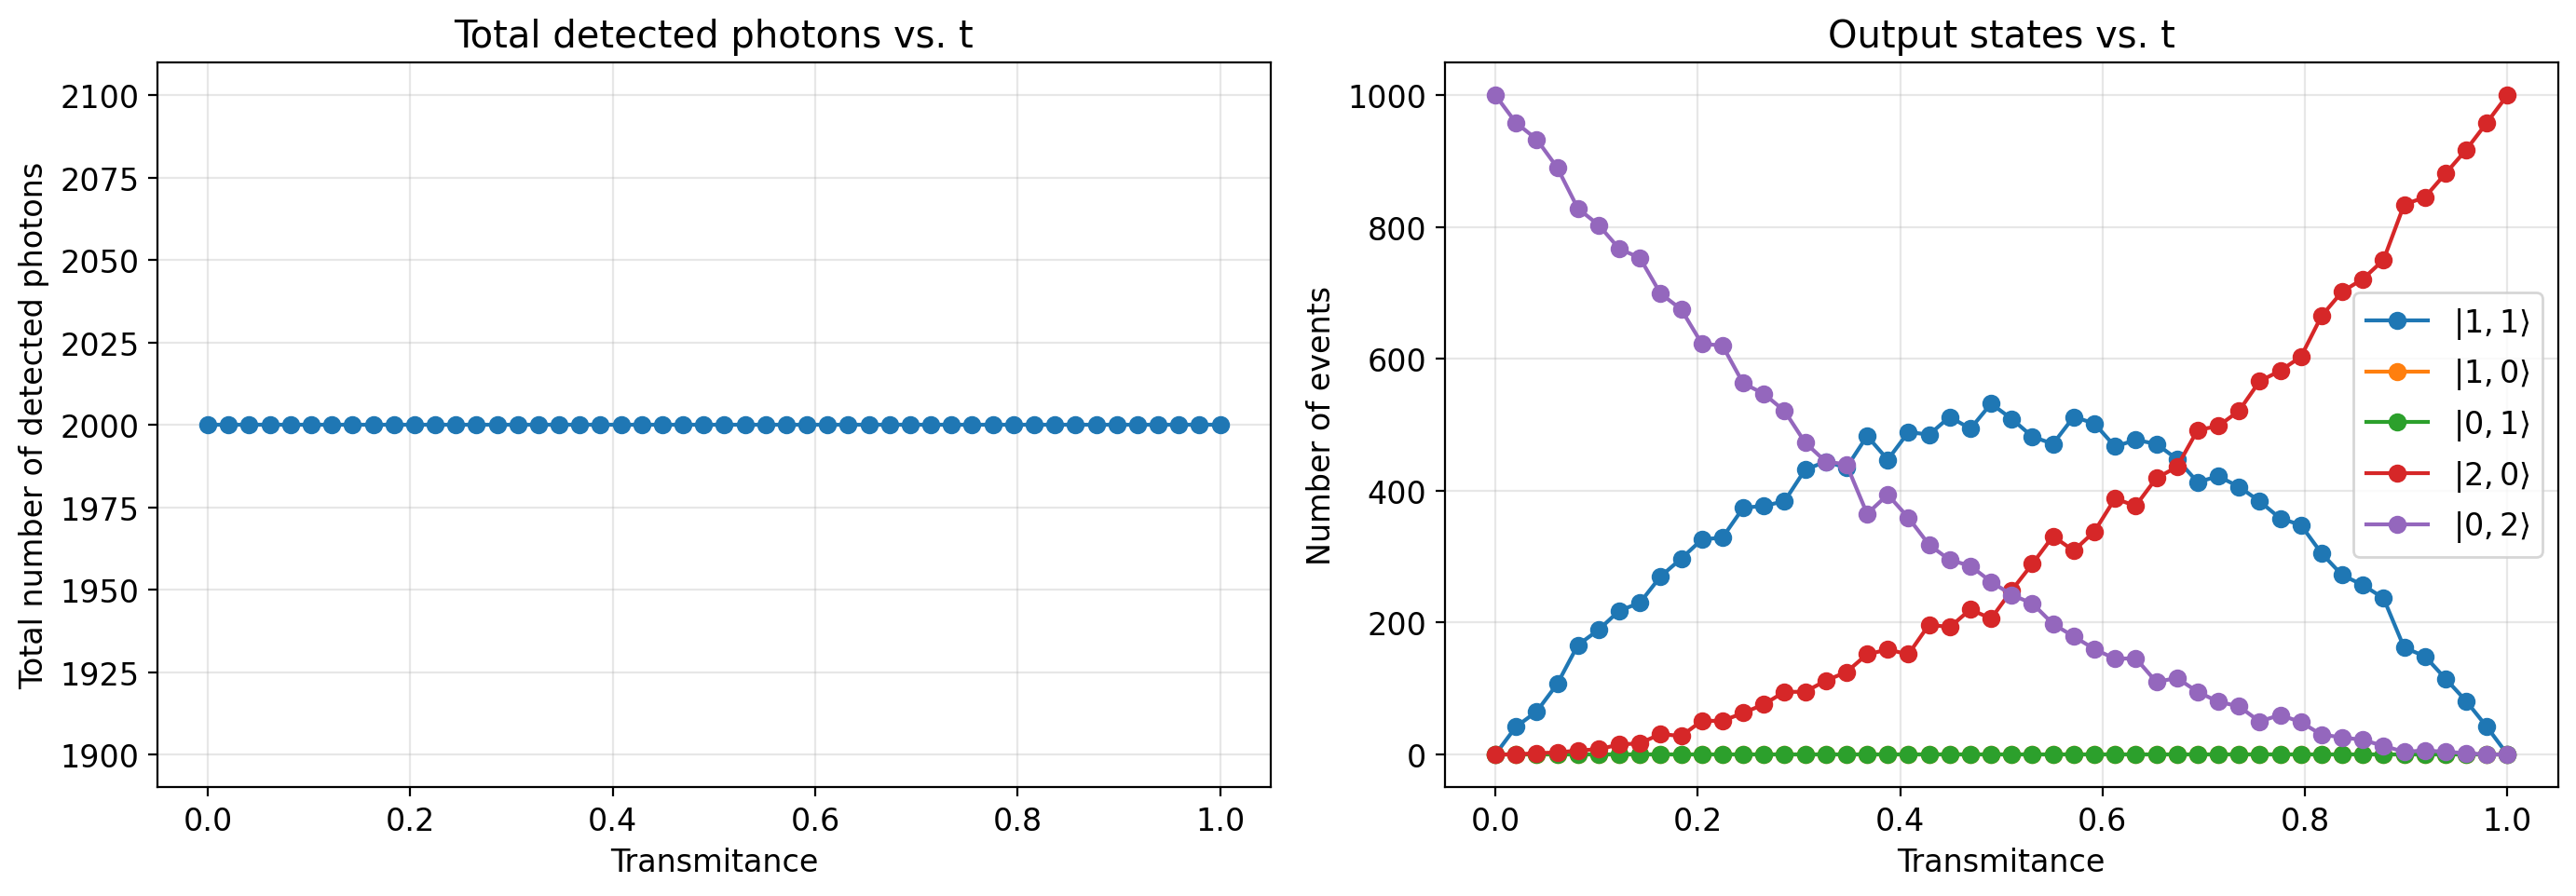

In [29]:
# Beam splitter defined from transmitance
def coincidence(r):
    return pcvl.Circuit(2) // pcvl.BS(pcvl.BS.r_to_theta(r))


# Reflectivity range
rs = np.linspace(0., 1, 50)

# Transmission
ts = 1 - rs

state = pcvl.BasicState('|2,0>')

result = []

n_samples = 1000

# Total number of detected photons for each theta
total_photons = []

for t in ts:

    proc = pcvl.Processor(
        "SLOS",
        coincidence(t),
        noise=pcvl.NoiseModel(brightness=1)
    )

    proc.with_input(state)

    proc.min_detected_photons_filter(0)

    sampler = pcvl.algorithm.Sampler(proc)

    samples = sampler.samples(n_samples)['results']

    counts = {
        '00': 0,
        '01': 0,
        '10': 0,
        '11': 0,
        '20': 0,
        '02': 0
    }

    for sample in samples:

        if sample == pcvl.BasicState('|0,0>'):
            counts['00'] += 1

        elif sample == pcvl.BasicState('|0,1>'):
            counts['01'] += 1

        elif sample == pcvl.BasicState('|1,0>'):
            counts['10'] += 1

        elif sample == pcvl.BasicState('|1,1>'):
            counts['11'] += 1

        elif sample == pcvl.BasicState('|2,0>'):
            counts['20'] += 1

        elif sample == pcvl.BasicState('|0,2>'):
            counts['02'] += 1

    result.append(counts)

    # Total number of detected photons for this theta
    N_photons = (
        counts['01']
        + counts['10']
        + 2*counts['11']
        + 2*counts['20']
        + 2*counts['02']
    )

    total_photons.append(N_photons)


# ---------------------------------------------------------
# Extract the individual counts
# ---------------------------------------------------------

n01 = [r['01'] for r in result]
n10 = [r['10'] for r in result]
n11 = [r['11'] for r in result]
n20 = [r['20'] for r in result]
n02 = [r['02'] for r in result]


# ---------------------------------------------------------
# Create two subplots
# ---------------------------------------------------------

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(14, 5)
)


# ---------------------------------------------------------
# Plot 1: Total number of photons
# ---------------------------------------------------------

ax1.plot(
    ts,
    total_photons,
    marker='o'
)

ax1.set_xlabel(r'Transmitance')
ax1.set_ylabel('Total number of detected photons')
ax1.set_title('Total detected photons vs. t')

ax1.grid(True)


# ---------------------------------------------------------
# Plot 2: Individual output states
# ---------------------------------------------------------

ax2.plot(
    ts,
    n11,
    marker='o',
    label=r'$|1,1\rangle$'
)

ax2.plot(
    ts,
    n10,
    marker='o',
    label=r'$|1,0\rangle$'
)

ax2.plot(
    ts,
    n01,
    marker='o',
    label=r'$|0,1\rangle$'
)

ax2.plot(
    ts,
    n20,
    marker='o',
    label=r'$|2,0\rangle$'
)

ax2.plot(
    ts,
    n02,
    marker='o',
    label=r'$|0,2\rangle$'
)

ax2.set_xlabel(r'Transmitance')
ax2.set_ylabel('Number of events')
ax2.set_title('Output states vs. t')

ax2.grid(True)
ax2.legend()


plt.tight_layout()
plt.show()

As expected for the PNR the number of counts is always the same, eventhough the states change as we alter the transmitance. We also dont see states $|1,0\rangle$ and $|0,1\rangle$ because we assume there are no losses.


Now we would like to check how the same thing works for the APD.

We will plot the photon number given by the detectors and correct it using the coincidence counts.

This is something I am not quite sure about, but from what I understood the correction factors reached by Gabo and Monkem are different. From Monkens PDF we have:

$$
M = (\frac{T}{2R} + \frac{R}{2T}) * C
$$

Where M is the corrected amount we need to add and C are the coincidences (assuming perfect efficiency).

Whereas, Gabos:

$$
M = \frac{T^4 + R^4}{2T^2R^2}
$$

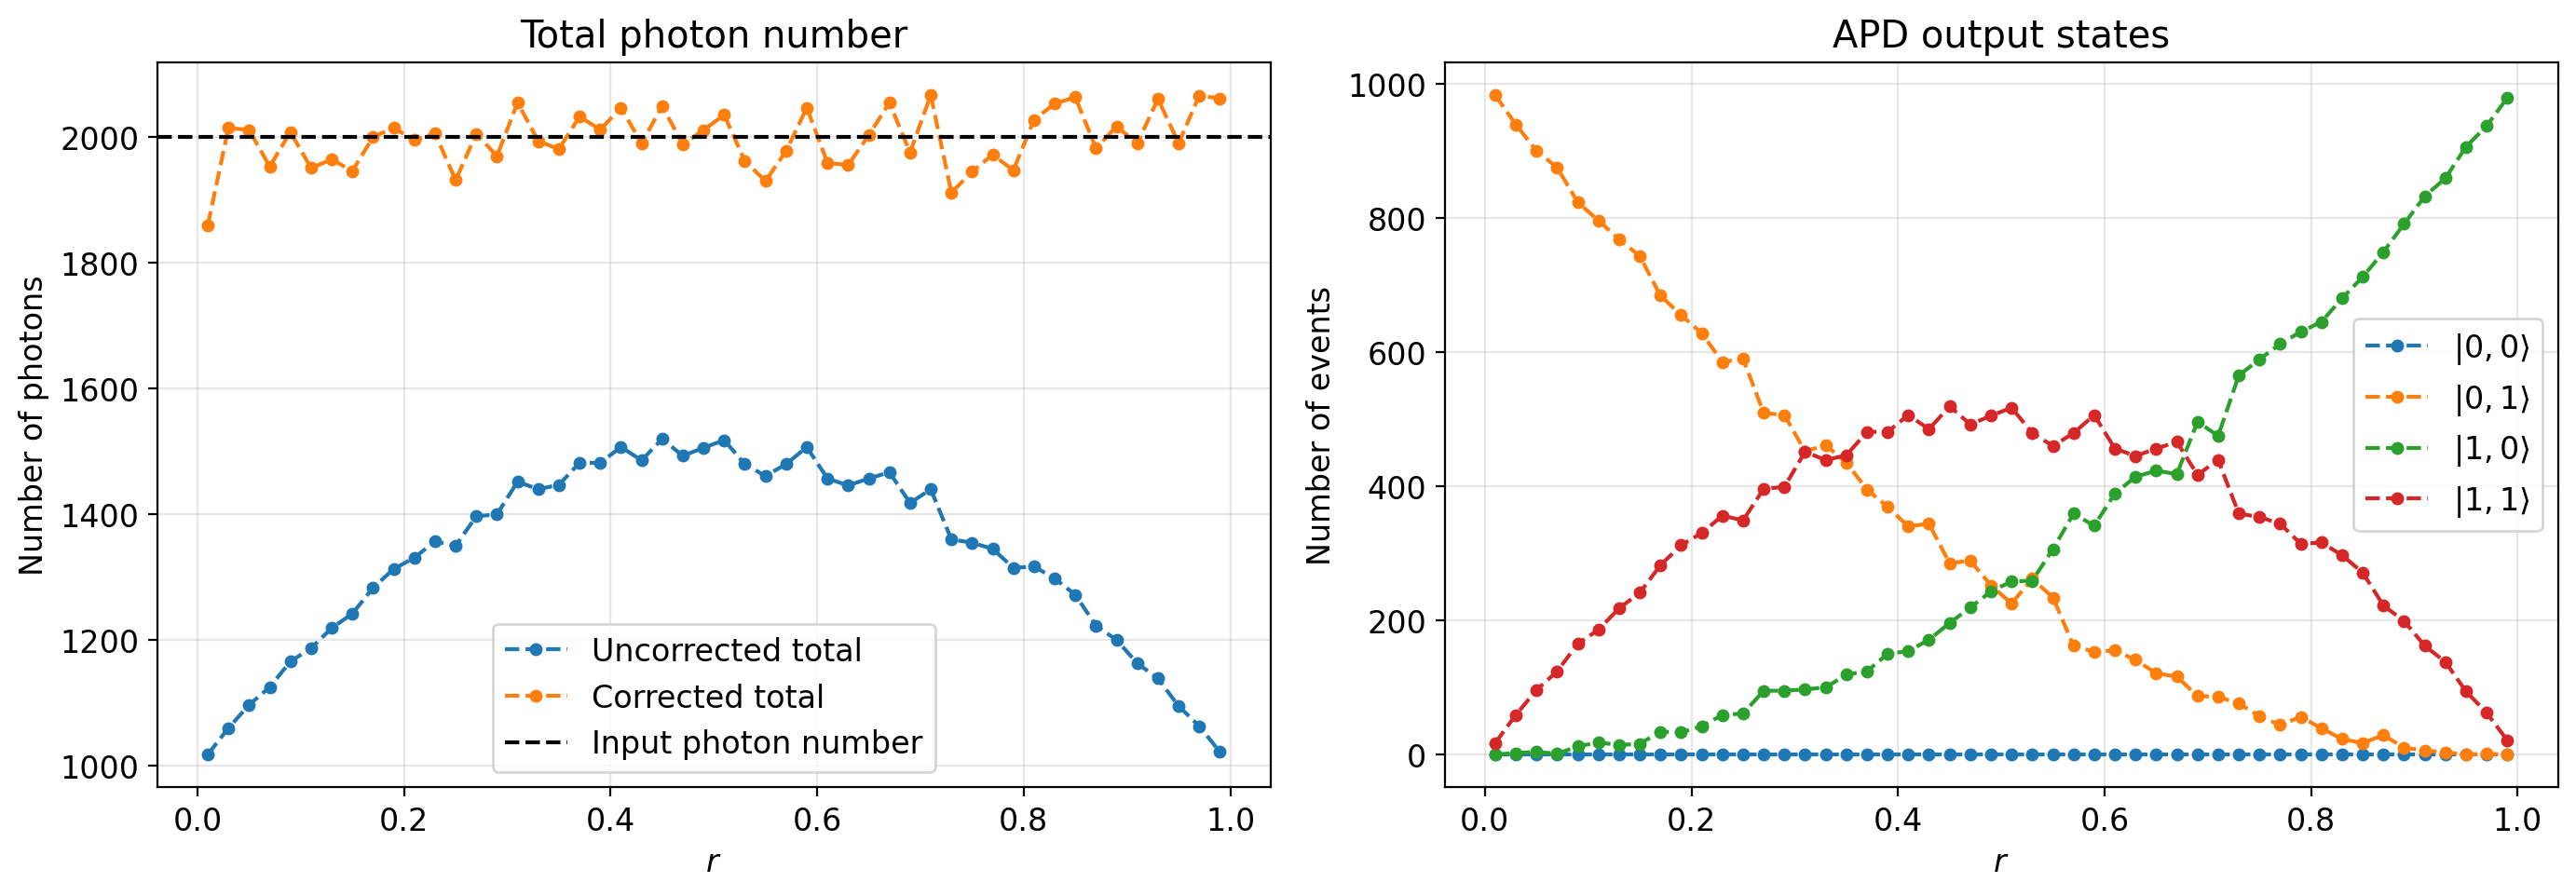

In [30]:
state = pcvl.BasicState('|2,0>')
result = []

n_samples = 1000

# Reflectivity range
rs = np.linspace(0.01, 0.99, 50)

# Total number of detected photons/clicks
total_photons_apd = []

# Corrected number of photons
corrected_photons = []

for r in rs:

    proc = pcvl.Processor(
        "SLOS",
        coincidence(r),
        noise=pcvl.NoiseModel(brightness=1.)
    )

    proc.with_input(state)

    proc.min_detected_photons_filter(0)

    # APD / threshold detectors
    proc.add(0, pcvl.Detector.threshold())
    proc.add(1, pcvl.Detector.threshold())

    sampler = pcvl.algorithm.Sampler(proc)

    samples = sampler.samples(n_samples)['results']

    # APD can only give 0 or 1 in each mode
    counts = {
        '00': 0,
        '01': 0,
        '10': 0,
        '11': 0
    }

    for sample in samples:

        if sample == pcvl.BasicState('|0,0>'):
            counts['00'] += 1

        elif sample == pcvl.BasicState('|0,1>'):
            counts['01'] += 1

        elif sample == pcvl.BasicState('|1,0>'):
            counts['10'] += 1

        elif sample == pcvl.BasicState('|1,1>'):
            counts['11'] += 1

    result.append(counts)

    # Number of detected photons/clicks
    N_photons = (
        counts['01']
        + counts['10']
        + 2 * counts['11']
    )

    # Coincidences
    C = counts['11']
    t = 1 - r

    # Correction
    M = (t / (2 * r) + r / (2 * t)) * C

    total_photons_apd.append(N_photons + M)
    corrected_photons.append(M)


# Convert to numpy arrays
total_photons_apd = np.array(total_photons_apd)
corrected_photons = np.array(corrected_photons)


# =========================================================
# Additional quantities for plotting
# =========================================================

# Uncorrected total number of photons
uncorrected_photons = np.array([
    counts['01'] + counts['10'] + 2 * counts['11']
    for counts in result
])

# Individual states
n00 = np.array([counts['00'] for counts in result])
n01 = np.array([counts['01'] for counts in result])
n10 = np.array([counts['10'] for counts in result])
n11 = np.array([counts['11'] for counts in result])


# =========================================================
# Plots
# =========================================================

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(14, 5)
)


# ---------------------------------------------------------
# Plot 1: Uncorrected and corrected total photons
# ---------------------------------------------------------

ax1.plot(
    rs,
    uncorrected_photons,
    'o--',
    linewidth=1.5,
    markersize=4,
    label='Uncorrected total'
)

ax1.plot(
    rs,
    total_photons_apd,
    'o--',
    linewidth=1.5,
    markersize=4,
    label='Corrected total'
)

# True number of photons entering the circuit
ax1.axhline(
    2 * n_samples,
    color='black',
    linestyle='--',
    linewidth=1.5,
    label='Input photon number'
)

ax1.set_xlabel(r'$r$')
ax1.set_ylabel('Number of photons')
ax1.set_title('Total photon number')

ax1.grid(True, alpha=0.3)
ax1.legend()


# ---------------------------------------------------------
# Plot 2: APD output states
# ---------------------------------------------------------

ax2.plot(
    rs,
    n00,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|0,0\rangle$'
)

ax2.plot(
    rs,
    n01,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|0,1\rangle$'
)

ax2.plot(
    rs,
    n10,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|1,0\rangle$'
)

ax2.plot(
    rs,
    n11,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|1,1\rangle$'
)

ax2.set_xlabel(r'$r$')
ax2.set_ylabel('Number of events')
ax2.set_title('APD output states')

ax2.grid(True, alpha=0.3)
ax2.legend()


plt.tight_layout()
plt.show()

As we can see the correction factor correctly gave us the total photon count. Although there are some fluctuation, which may be expected since the correction factor is based on the Coincidence counts which fluctuate in each run and maybe because of numerical uncertanties given that $r$ and $t$ are floating numbers.

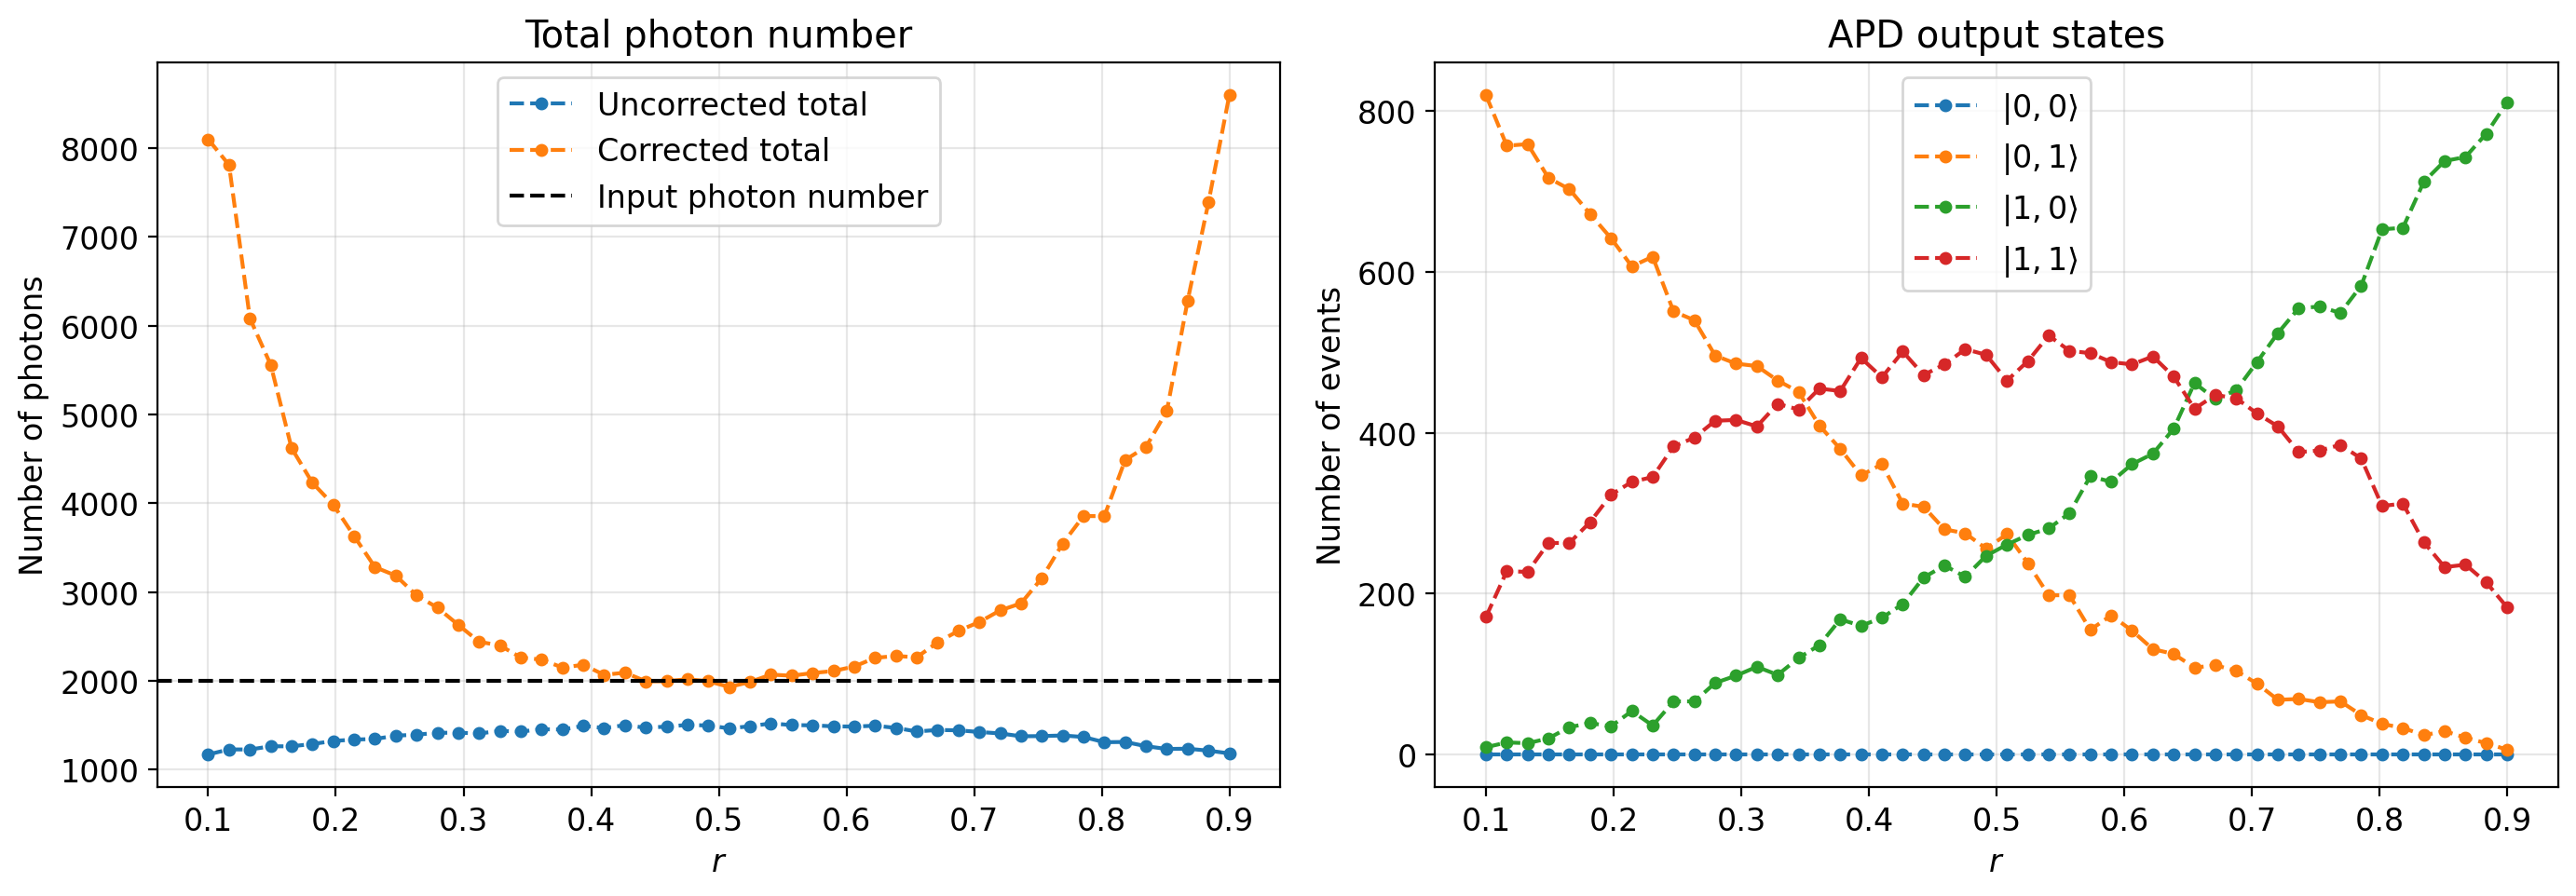

In [31]:
state = pcvl.BasicState('|2,0>')
result = []

n_samples = 1000

# Reflectivity range
rs = np.linspace(0.1, 0.9, 50)

# Total number of detected photons/clicks
total_photons_apd = []

# Corrected number of photons
corrected_photons = []

for r in rs:

    proc = pcvl.Processor(
        "SLOS",
        coincidence(r)
    )

    proc.with_input(state)

    proc.min_detected_photons_filter(0)

    # APD / threshold detectors
    proc.add(0, pcvl.Detector.threshold())
    proc.add(1, pcvl.Detector.threshold())

    sampler = pcvl.algorithm.Sampler(proc)

    samples = sampler.samples(n_samples)['results']

    # APD can only give 0 or 1 in each mode
    counts = {
        '00': 0,
        '01': 0,
        '10': 0,
        '11': 0
    }

    for sample in samples:

        if sample == pcvl.BasicState('|0,0>'):
            counts['00'] += 1

        elif sample == pcvl.BasicState('|0,1>'):
            counts['01'] += 1

        elif sample == pcvl.BasicState('|1,0>'):
            counts['10'] += 1

        elif sample == pcvl.BasicState('|1,1>'):
            counts['11'] += 1

    result.append(counts)

    # Number of detected photons/clicks
    N_photons = (
        counts['01']
        + counts['10']
        + 2 * counts['11']
    )

    # Coincidences
    C = counts['11']
    t = 1 - r

    # OLD correction
    M = ((t**4 + r**4) / (2 * t**2 * r**2)) * C

    total_photons_apd.append(N_photons + M)
    corrected_photons.append(M)


# Convert to numpy arrays
total_photons_apd = np.array(total_photons_apd)
corrected_photons = np.array(corrected_photons)


# =========================================================
# Additional quantities for plotting
# =========================================================

# Uncorrected total number of photons
uncorrected_photons = np.array([
    counts['01'] + counts['10'] + 2 * counts['11']
    for counts in result
])

# Individual states
n00 = np.array([counts['00'] for counts in result])
n01 = np.array([counts['01'] for counts in result])
n10 = np.array([counts['10'] for counts in result])
n11 = np.array([counts['11'] for counts in result])


# =========================================================
# Plots
# =========================================================

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(14, 5)
)


# ---------------------------------------------------------
# Plot 1: Uncorrected and corrected total photons
# ---------------------------------------------------------

ax1.plot(
    rs,
    uncorrected_photons,
    'o--',
    linewidth=1.5,
    markersize=4,
    label='Uncorrected total'
)

ax1.plot(
    rs,
    total_photons_apd,
    'o--',
    linewidth=1.5,
    markersize=4,
    label='Corrected total'
)

# True number of photons entering the circuit
ax1.axhline(
    2 * n_samples,
    color='black',
    linestyle='--',
    linewidth=1.5,
    label='Input photon number'
)

ax1.set_xlabel(r'$r$')
ax1.set_ylabel('Number of photons')
ax1.set_title('Total photon number')

ax1.grid(True, alpha=0.3)
ax1.legend()


# ---------------------------------------------------------
# Plot 2: APD output states
# ---------------------------------------------------------

ax2.plot(
    rs,
    n00,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|0,0\rangle$'
)

ax2.plot(
    rs,
    n01,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|0,1\rangle$'
)

ax2.plot(
    rs,
    n10,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|1,0\rangle$'
)

ax2.plot(
    rs,
    n11,
    'o--',
    linewidth=1.5,
    markersize=4,
    label=r'$|1,1\rangle$'
)

ax2.set_xlabel(r'$r$')
ax2.set_ylabel('Number of events')
ax2.set_title('APD output states')

ax2.grid(True, alpha=0.3)
ax2.legend()


plt.tight_layout()
plt.show()

For the second corrrection factor we see it does work fairly well in the range of (0.4 - 0.6). In this case the problem is due to the the denominator $r^2*t^2$, where $r \in [0,1]$ and $t = 1-r$.

I still believe, if this is found to be interesting, that we could explore what would happen if we added changing detector efficiencies and we can even see wheter or not it is possible to define a statistics for the light which enters our system.

### AI use:
Chat gpt was used to correct the codes.